<a href="https://colab.research.google.com/github/srabani-khuntia/Machine-Learning-Lab/blob/main/Assignment-6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ASSIGNMENT - 6: Decision Tree & Random Forest Models**



In [ ]:
# Importing libraries for data manipulation
import pandas as pd
import numpy as np

# Importing libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Importing train-test split
from sklearn.model_selection import train_test_split

# Importing classification algorithms
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Importing regression algorithms
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Importing classification evaluation metrics
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc,
    classification_report
)

# Importing regression evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Setting visualization style
sns.set_style("whitegrid")

# Setting display options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("All libraries imported successfully.")

All libraries imported successfully.


##### **1. After preprocessing, split the dataset as training dataset 80% and test dataset 20%. Implement Decision tree classifier and measures its performances such as Confusion Matrix, Precision, Recall, accuracy, f1-score and ROC curve. Give the conclusion statements according to the performances of the model.**

In [ ]:
# Loading the classification dataset
from google.colab import files

uploaded = files.upload()
campus_df = pd.read_csv('campus_preprocessed.csv')

print("Dataset loaded successfully!")

Saving campus_preprocessed.csv to campus_preprocessed (1).csv
Dataset loaded successfully!


In [ ]:
# Separating independent features and target variable
X = campus_df.drop('placed', axis=1)
y = campus_df['placed']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

# Checking target class distribution
print("\nTarget Class Distribution:")
print(y.value_counts())

print("\nTarget Class Distribution in Percentage:")
print(y.value_counts(normalize=True) * 100)

Features Shape: (100000, 33)
Target Shape: (100000,)

Target Class Distribution:
placed
1    84432
0    15568
Name: count, dtype: int64

Target Class Distribution in Percentage:
placed
1    84.432
0    15.568
Name: proportion, dtype: float64


In [ ]:
# Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Displaying the dimensions of the split datasets
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

# Checking target distribution after splitting
print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Features Shape: (80000, 33)
Testing Features Shape: (20000, 33)
Training Target Shape: (80000,)
Testing Target Shape: (20000,)

Training Target Distribution:
placed
1    67546
0    12454
Name: count, dtype: int64

Testing Target Distribution:
placed
1    16886
0     3114
Name: count, dtype: int64


### Implementing Decision Tree Classifier

A Decision Tree Classifier is a supervised machine learning algorithm used for classification tasks.

It creates a tree-like structure by repeatedly splitting the dataset based on feature conditions. Each internal node represents a decision based on a feature, while the leaf nodes represent the predicted class.

In [ ]:
# Creating the Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

# Training the model
dt_classifier.fit(X_train, y_train)

# Generating predictions for the test dataset
y_pred_dt = dt_classifier.predict(X_test)

# Generating probabilities for the positive class
y_prob_dt = dt_classifier.predict_proba(X_test)[:, 1]

print("Decision Tree Classifier trained successfully.")

Decision Tree Classifier trained successfully.


In [ ]:
# Creating a DataFrame to compare actual and predicted values
dt_predictions = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred_dt
})

# Displaying the first 10 predictions
print("Decision Tree Classifier - Actual vs Predicted Values")
print(dt_predictions.head(10))

Decision Tree Classifier - Actual vs Predicted Values
   Actual  Predicted
0       1          1
1       0          1
2       1          1
3       0          0
4       1          1
5       1          1
6       1          1
7       1          1
8       1          1
9       1          1


In [ ]:
# Calculating classification performance metrics
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt)
dt_recall = recall_score(y_test, y_pred_dt)
dt_f1 = f1_score(y_test, y_pred_dt)

# Calculating confusion matrix
dt_cm = confusion_matrix(y_test, y_pred_dt)

# Calculating ROC curve and AUC
fpr_dt, tpr_dt, thresholds_dt = roc_curve(y_test, y_prob_dt)
dt_auc = auc(fpr_dt, tpr_dt)

# Displaying performance metrics
print("Decision Tree Classifier Performance")
print("------------------------------------")
print(f"Accuracy  : {dt_accuracy:.4f}")
print(f"Precision : {dt_precision:.4f}")
print(f"Recall    : {dt_recall:.4f}")
print(f"F1-Score  : {dt_f1:.4f}")
print(f"ROC-AUC   : {dt_auc:.4f}")

Decision Tree Classifier Performance
------------------------------------
Accuracy  : 0.7871
Precision : 0.8796
Recall    : 0.8664
F1-Score  : 0.8730
ROC-AUC   : 0.6117


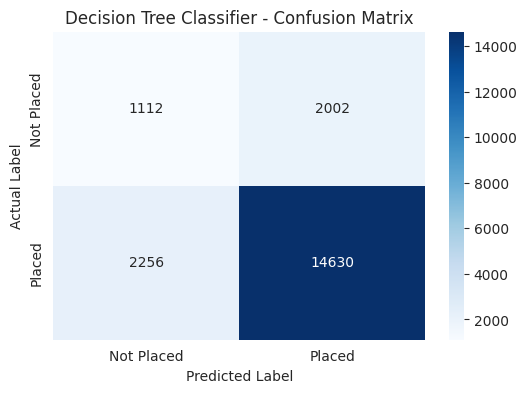

In [ ]:
# Displaying the confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Placed', 'Placed'],
    yticklabels=['Not Placed', 'Placed']
)

plt.title('Decision Tree Classifier - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

In [ ]:
# Generating the classification report
print("Decision Tree Classifier - Classification Report")

print(classification_report(
    y_test,
    y_pred_dt,
    target_names=['Not Placed', 'Placed']
))

Decision Tree Classifier - Classification Report
              precision    recall  f1-score   support

  Not Placed       0.33      0.36      0.34      3114
      Placed       0.88      0.87      0.87     16886

    accuracy                           0.79     20000
   macro avg       0.60      0.61      0.61     20000
weighted avg       0.79      0.79      0.79     20000



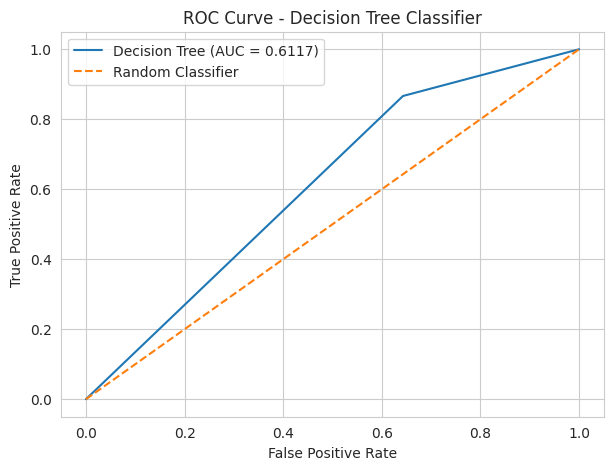

In [ ]:
# Plotting the ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f'Decision Tree (AUC = {dt_auc:.4f})'
)

# Plotting the random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Decision Tree Classifier')
plt.legend()
plt.grid(True)
plt.show()


### Conclusion – Decision Tree Classifier

- Achieved an accuracy of **78.71%**, indicating moderate overall classification performance.
- Obtained a precision of **87.96%** and recall of **86.64%** for the Placed class.
- Achieved an F1-score of **87.30%**, indicating a reasonable balance between precision and recall.
- Obtained a ROC-AUC score of **0.6117**, indicating limited ability to distinguish between the Placed and Not Placed classes.
- Correctly classified **14,630 placed students** and **1,112 students who were not placed**.
- The model demonstrated better performance in identifying the majority class (Placed) than the minority class (Not Placed), for which the recall was only 36%.
- Therefore, the Decision Tree Classifier showed moderate classification performance but had difficulty identifying students belonging to the Not Placed category.


##### **2. After preprocessing, split the dataset as training dataset 80% and test dataset 20%. Implement Random forest classifier and measures its performances such as Confusion Matrix, Precision, Recall, accuracy, f1-score and ROC curve. Give the conclusion statements according to the performances of the model.**

### Implementing Random Forest Classifier

Random Forest Classifier is an ensemble learning algorithm that combines multiple Decision Trees to make predictions.

Each tree is trained using a different sample of the training data. The final classification is determined through majority voting among the individual trees.

This approach generally improves model stability and reduces overfitting compared to a single Decision Tree.

In [ ]:
# Creating the Random Forest Classifier
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    random_state=42,
    n_jobs=-1
)

# Training the model
rf_classifier.fit(X_train, y_train)

# Generating predictions for the test dataset
y_pred_rf = rf_classifier.predict(X_test)

# Generating probabilities for the positive class
y_prob_rf = rf_classifier.predict_proba(X_test)[:, 1]

print("Random Forest Classifier trained successfully.")

Random Forest Classifier trained successfully.


In [ ]:
# Creating a DataFrame to compare actual and predicted values
rf_predictions = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred_rf
})

# Displaying the first 10 predictions
print("Random Forest Classifier - Actual vs Predicted Values")
display(rf_predictions.head(10))

Random Forest Classifier - Actual vs Predicted Values


,Actual,Predicted
0,1,1
1,0,1
2,1,1
3,0,1
4,1,1
5,1,1
6,1,1
7,1,1
8,1,1
9,1,1


In [ ]:
# Calculating classification performance metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)

# Calculating confusion matrix
rf_cm = confusion_matrix(y_test, y_pred_rf)

# Calculating ROC curve and AUC
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, y_prob_rf)
rf_auc = auc(fpr_rf, tpr_rf)

# Displaying performance metrics
print("Random Forest Classifier Performance")
print("------------------------------------")
print(f"Accuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1-Score  : {rf_f1:.4f}")
print(f"ROC-AUC   : {rf_auc:.4f}")

Random Forest Classifier Performance
------------------------------------
Accuracy  : 0.8546
Precision : 0.8656
Recall    : 0.9799
F1-Score  : 0.9192
ROC-AUC   : 0.8245


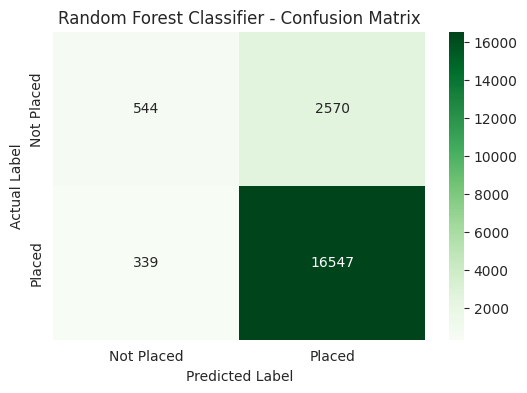

In [ ]:
# Displaying the confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Not Placed', 'Placed'],
    yticklabels=['Not Placed', 'Placed']
)

plt.title('Random Forest Classifier - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

In [ ]:
# Generating the classification report
print("Random Forest Classifier - Classification Report")

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=['Not Placed', 'Placed']
))

Random Forest Classifier - Classification Report
              precision    recall  f1-score   support

  Not Placed       0.62      0.17      0.27      3114
      Placed       0.87      0.98      0.92     16886

    accuracy                           0.85     20000
   macro avg       0.74      0.58      0.60     20000
weighted avg       0.83      0.85      0.82     20000



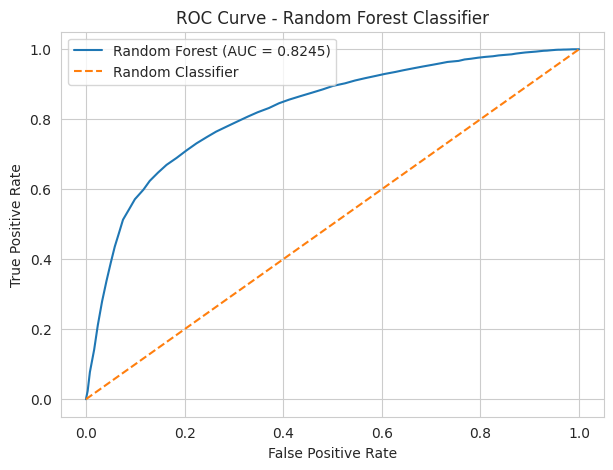

In [ ]:
# Plotting the ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f'Random Forest (AUC = {rf_auc:.4f})'
)

# Plotting the random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest Classifier')
plt.legend()
plt.grid(True)
plt.show()


### Conclusion – Random Forest Classifier

- Achieved an accuracy of **85.46%**, indicating good overall classification performance.
- Obtained a precision of **86.56%** and recall of **97.99%** for the Placed class.
- Achieved an F1-score of **91.92%**, indicating strong classification performance.
- Obtained a ROC-AUC score of **0.8245**, demonstrating good ability to distinguish between the Placed and Not Placed classes.
- Correctly classified **16,547 placed students** and **544 students who were not placed**.
- The model demonstrated very high recall for the Placed class but comparatively poor performance in identifying the minority class (Not Placed), with only 17% recall.
- Therefore, the Random Forest Classifier achieved good overall classification performance, particularly in identifying placed students, but showed a tendency towards predicting the majority class.


##### **3. After preprocessing, split the dataset as training dataset 80% and test dataset 20%. Implement Decision Tree regressor and measures its performances such as MAE, MSE, RMSE, and R2. Give the conclusion statements according to the performances of the model.**

In [ ]:
# Loading the classification dataset
from google.colab import files

uploaded = files.upload()
uber_df = pd.read_csv('uber_preprocessed.csv')

print("Dataset loaded successfully!")

Saving uber_preprocessed.csv to uber_preprocessed (1).csv
Dataset loaded successfully!


In [ ]:
# Separate independent features and target variable
X_reg = uber_df.drop(columns=['fare_amount'])
y_reg = uber_df['fare_amount']

print("Independent Features Shape:", X_reg.shape)
print("Target Variable Shape:", y_reg.shape)

print("\nTarget Variable Statistics:")
display(y_reg.describe())

Independent Features Shape: (194918, 10)
Target Variable Shape: (194918,)

Target Variable Statistics:


,fare_amount
count,194918.000000
mean,11.322388
std,9.608892
min,0.010000
25%,6.000000
50%,8.500000
75%,12.500000
max,499.000000


In [ ]:
# Train-Test split

# Split the dataset into 80% training and 20% testing
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Training Features Shape:", X_train_reg.shape)
print("Testing Features Shape:", X_test_reg.shape)

print("\nTraining Target Shape:", y_train_reg.shape)
print("Testing Target Shape:", y_test_reg.shape)

Training Features Shape: (155934, 10)
Testing Features Shape: (38984, 10)

Training Target Shape: (155934,)
Testing Target Shape: (38984,)


### Implementing Decision Tree Regressor

Decision Tree Regressor is a supervised machine learning algorithm used for predicting continuous numerical values.

It divides the dataset into smaller regions based on feature conditions. The predicted value at each leaf node is generally calculated using the average target value of the training samples belonging to that leaf.

In [ ]:
# Creating the Decision Tree Regressor
dt_regressor = DecisionTreeRegressor(
    criterion='squared_error',
    random_state=42
)

# Training the model
dt_regressor.fit(X_train_reg, y_train_reg)

# Generating predictions for the test dataset
y_pred_dt_reg = dt_regressor.predict(X_test_reg)

print("Decision Tree Regressor trained successfully.")

Decision Tree Regressor trained successfully.


In [ ]:
# Creating a DataFrame to compare actual and predicted values
dt_reg_predictions = pd.DataFrame({
    'Actual Fare': y_test_reg.values,
    'Predicted Fare': y_pred_dt_reg
})

# Displaying the first 10 predictions
print("Decision Tree Regressor - Actual vs Predicted Values")
display(dt_reg_predictions.head(10))

Decision Tree Regressor - Actual vs Predicted Values


,Actual Fare,Predicted Fare
0,4.1,4.9
1,14.1,11.7
2,3.5,3.5
3,11.5,6.0
4,8.0,7.5
5,26.5,30.8
6,15.0,23.5
7,15.0,19.5
8,31.7,13.3
9,8.9,12.5


In [ ]:
# Calculating regression performance metrics
dt_mae = mean_absolute_error(y_test_reg, y_pred_dt_reg)
dt_mse = mean_squared_error(y_test_reg, y_pred_dt_reg)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test_reg, y_pred_dt_reg)

# Displaying performance metrics
print("Decision Tree Regressor Performance")
print("-----------------------------------")
print(f"MAE  : {dt_mae:.4f}")
print(f"MSE  : {dt_mse:.4f}")
print(f"RMSE : {dt_rmse:.4f}")
print(f"R2   : {dt_r2:.4f}")

Decision Tree Regressor Performance
-----------------------------------
MAE  : 2.6526
MSE  : 41.6830
RMSE : 6.4562
R2   : 0.5497



### Conclusion – Decision Tree Regressor

- Achieved a Mean Absolute Error (MAE) of **2.6526**, indicating an average prediction error of approximately 2.65 fare units.
- Obtained a Mean Squared Error (MSE) of **41.6830**, representing the average squared prediction error.
- Achieved a Root Mean Squared Error (RMSE) of **6.4562**, indicating the magnitude of prediction errors in the original fare units.
- Obtained an R² Score of **0.5497**, indicating that the model explains approximately **54.97%** of the variation in Uber fare amounts.
- The model demonstrated moderate predictive capability but still produced noticeable prediction errors.
- Therefore, the Decision Tree Regressor was able to capture some relationships between the input features and fare amounts, but its predictive performance could be improved.


##### **4. After preprocessing, split the dataset as training dataset 80% and test dataset 20%. Implement Random forest regressor and measures its performances such as MAE, MSE, RMSE, and R2. Give the conclusion statements according to the performances of the model.**

### Implementing Random Forest Regressor

Random Forest Regressor is an ensemble learning algorithm that combines multiple Decision Tree Regressors to predict continuous numerical values.

Each tree is trained using a different sample of the training data. The final prediction is obtained by averaging the predictions of all individual trees, which generally improves model stability and reduces overfitting.

In [ ]:
# Creating the Random Forest Regressor
rf_regressor = RandomForestRegressor(
    n_estimators=100,
    criterion='squared_error',
    random_state=42,
    n_jobs=-1
)

# Training the model
rf_regressor.fit(X_train_reg, y_train_reg)

# Generating predictions for the test dataset
y_pred_rf_reg = rf_regressor.predict(X_test_reg)

print("Random Forest Regressor trained successfully.")

Random Forest Regressor trained successfully.


In [ ]:
# Creating a DataFrame to compare actual and predicted values
rf_reg_predictions = pd.DataFrame({
    'Actual Fare': y_test_reg.values,
    'Predicted Fare': y_pred_rf_reg
})

# Displaying the first 10 predictions
print("Random Forest Regressor - Actual vs Predicted Values")
display(rf_reg_predictions.head(10))

Random Forest Regressor - Actual vs Predicted Values


,Actual Fare,Predicted Fare
0,4.1,5.6880
1,14.1,13.4700
2,3.5,5.0350
3,11.5,5.6300
4,8.0,7.9400
5,26.5,25.7793
6,15.0,15.3500
7,15.0,15.8300
8,31.7,13.7190
9,8.9,12.2120


In [ ]:
# Calculating regression performance metrics
rf_mae = mean_absolute_error(y_test_reg, y_pred_rf_reg)
rf_mse = mean_squared_error(y_test_reg, y_pred_rf_reg)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test_reg, y_pred_rf_reg)

# Displaying performance metrics
print("Random Forest Regressor Performance")
print("-----------------------------------")
print(f"MAE  : {rf_mae:.4f}")
print(f"MSE  : {rf_mse:.4f}")
print(f"RMSE : {rf_rmse:.4f}")
print(f"R2   : {rf_r2:.4f}")

Random Forest Regressor Performance
-----------------------------------
MAE  : 1.8379
MSE  : 13.9560
RMSE : 3.7358
R2   : 0.8492



### Conclusion – Random Forest Regressor

- Achieved a Mean Absolute Error (MAE) of **1.8379**, indicating an average prediction error of approximately 1.84 fare units.
- Obtained a Mean Squared Error (MSE) of **13.9560**, indicating comparatively lower squared prediction errors.
- Achieved a Root Mean Squared Error (RMSE) of **3.7358**, indicating lower prediction errors in the original fare units.
- Obtained an R² Score of **0.8492**, indicating that the model explains approximately **84.92%** of the variation in Uber fare amounts.
- The model demonstrated strong predictive capability, with relatively low error values and a high R² Score.
- Therefore, the Random Forest Regressor performed effectively in predicting Uber fare amounts by combining predictions from multiple Decision Trees.


##### **5. Plot bar diagram for decision tree and random forest classifiers for comparisons representation of Confusion Matrix, Precision, Recall, accuracy, f1-score and ROC curve.**

In [ ]:
# Creating a comparison table for classification metrics
classification_comparison = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'ROC-AUC'
    ],
    'Decision Tree': [
        dt_accuracy,
        dt_precision,
        dt_recall,
        dt_f1,
        dt_auc
    ],
    'Random Forest': [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_auc
    ]
})

# Displaying the comparison table
print("Classification Performance Comparison")
display(classification_comparison.round(4))

Classification Performance Comparison


,Metric,Decision Tree,Random Forest
0,Accuracy,0.7871,0.8546
1,Precision,0.8796,0.8656
2,Recall,0.8664,0.9799
3,F1-Score,0.8730,0.9192
4,ROC-AUC,0.6117,0.8245


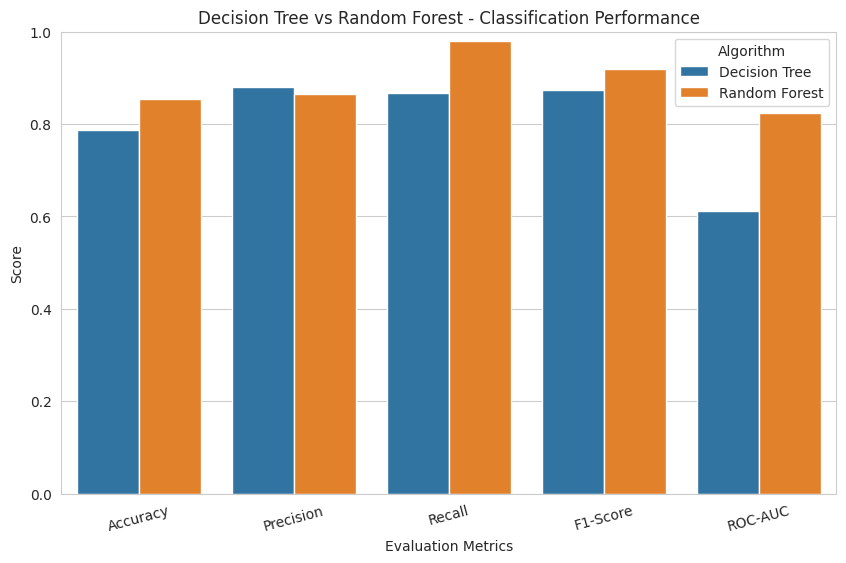

In [ ]:
# Converting the comparison table into long format
classification_plot = classification_comparison.melt(
    id_vars='Metric',
    var_name='Algorithm',
    value_name='Score'
)

# Plotting the bar diagram
plt.figure(figsize=(10, 6))

sns.barplot(
    data=classification_plot,
    x='Metric',
    y='Score',
    hue='Algorithm'
)

plt.title('Decision Tree vs Random Forest - Classification Performance')
plt.xlabel('Evaluation Metrics')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.legend(title='Algorithm')
plt.xticks(rotation=15)
plt.show()

In [ ]:
# Extracting confusion matrix values for Decision Tree
dt_tn, dt_fp, dt_fn, dt_tp = dt_cm.ravel()

# Extracting confusion matrix values for Random Forest
rf_tn, rf_fp, rf_fn, rf_tp = rf_cm.ravel()

# Creating a comparison table
confusion_comparison = pd.DataFrame({
    'Category': [
        'True Negative',
        'False Positive',
        'False Negative',
        'True Positive'
    ],
    'Decision Tree': [
        dt_tn,
        dt_fp,
        dt_fn,
        dt_tp
    ],
    'Random Forest': [
        rf_tn,
        rf_fp,
        rf_fn,
        rf_tp
    ]
})

# Displaying the comparison table
print("Confusion Matrix Comparison")
display(confusion_comparison)

Confusion Matrix Comparison


,Category,Decision Tree,Random Forest
0,True Negative,1112,544
1,False Positive,2002,2570
2,False Negative,2256,339
3,True Positive,14630,16547


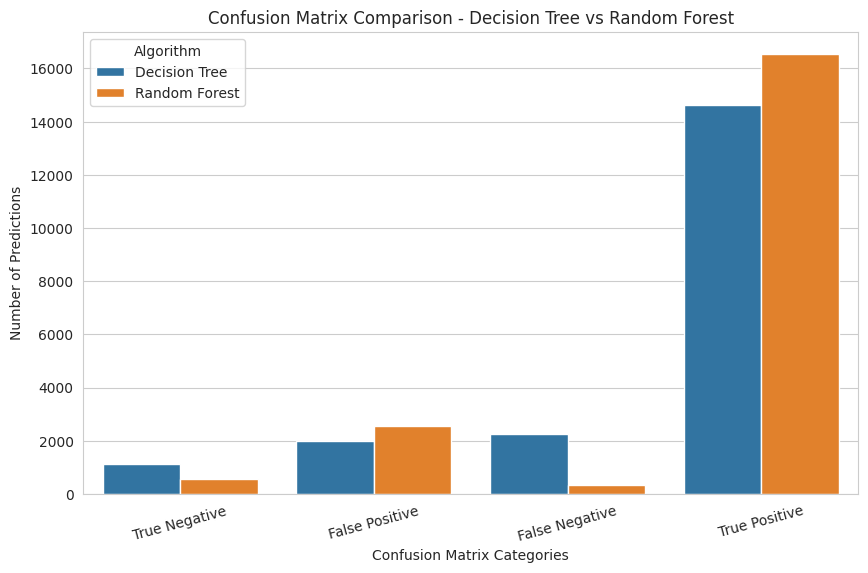

In [ ]:
# Converting the confusion matrix comparison into long format
confusion_plot = confusion_comparison.melt(
    id_vars='Category',
    var_name='Algorithm',
    value_name='Count'
)

# Plotting the bar diagram
plt.figure(figsize=(10, 6))

sns.barplot(
    data=confusion_plot,
    x='Category',
    y='Count',
    hue='Algorithm'
)

plt.title('Confusion Matrix Comparison - Decision Tree vs Random Forest')
plt.xlabel('Confusion Matrix Categories')
plt.ylabel('Number of Predictions')
plt.legend(title='Algorithm')
plt.xticks(rotation=15)
plt.show()

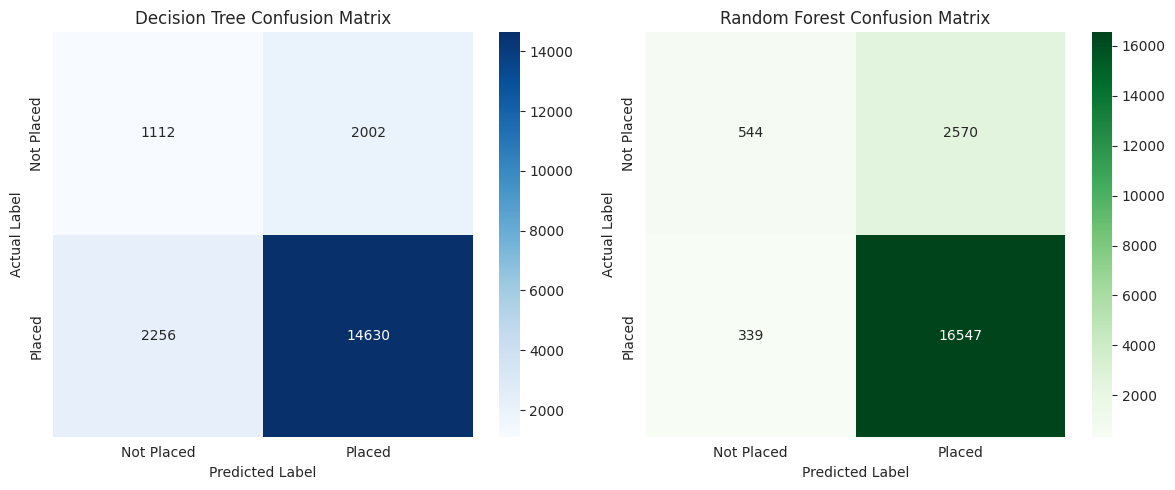

In [ ]:
# Comparing the confusion matrices of both classifiers
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Decision Tree Confusion Matrix
sns.heatmap(
    dt_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Placed', 'Placed'],
    yticklabels=['Not Placed', 'Placed'],
    ax=axes[0]
)

axes[0].set_title('Decision Tree Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

# Random Forest Confusion Matrix
sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Not Placed', 'Placed'],
    yticklabels=['Not Placed', 'Placed'],
    ax=axes[1]
)

axes[1].set_title('Random Forest Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

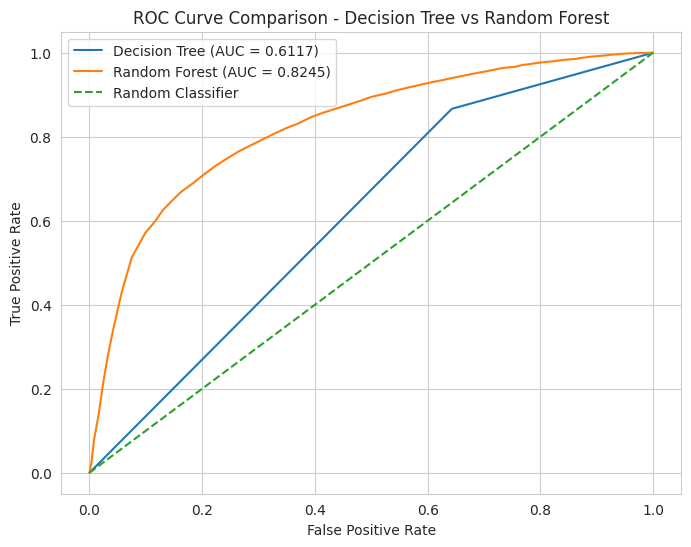

In [ ]:
# Plotting ROC curves of both classifiers
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f'Decision Tree (AUC = {dt_auc:.4f})'
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f'Random Forest (AUC = {rf_auc:.4f})'
)

# Plotting the random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison - Decision Tree vs Random Forest')
plt.legend()
plt.grid(True)
plt.show()


### Conclusion – Classification Comparison

- Decision Tree Classifier and Random Forest Classifier were compared using Accuracy, Precision, Recall, F1-Score, ROC-AUC and Confusion Matrix.
- Random Forest achieved higher accuracy (**85.46%**) compared to Decision Tree (**78.71%**).
- Decision Tree achieved slightly higher precision (**87.96%**) than Random Forest (**86.56%**).
- Random Forest achieved significantly higher recall (**97.99%**) and F1-score (**91.92%**) compared to Decision Tree.
- Random Forest also obtained a higher ROC-AUC score of **0.8245**, compared to **0.6117** for Decision Tree, indicating better class discrimination.
- From the confusion matrices, Random Forest correctly identified **16,547 placed students**, whereas Decision Tree correctly identified **14,630**.
- However, Decision Tree identified more students belonging to the Not Placed category, with 1,112 True Negatives compared to 544 for Random Forest.
- Both models showed difficulty identifying the minority class (Not Placed), indicating the influence of class imbalance on classification performance.
- Therefore, Random Forest demonstrated better overall classification performance, particularly in identifying placed students, while Decision Tree performed slightly better in identifying students who were not placed.


##### **6. Plot bar diagram for decision tree and random forest regressor for comparisons representation of MAE, MSE, RMSE, and R2.**

In [ ]:
# Creating a comparison table for regression metrics
regression_comparison = pd.DataFrame({
    'Metric': [
        'MAE',
        'MSE',
        'RMSE',
        'R2 Score'
    ],
    'Decision Tree': [
        dt_mae,
        dt_mse,
        dt_rmse,
        dt_r2
    ],
    'Random Forest': [
        rf_mae,
        rf_mse,
        rf_rmse,
        rf_r2
    ]
})

# Displaying the comparison table
print("Regression Performance Comparison")
display(regression_comparison.round(4))

Regression Performance Comparison


,Metric,Decision Tree,Random Forest
0,MAE,2.6526,1.8379
1,MSE,41.6830,13.9560
2,RMSE,6.4562,3.7358
3,R2 Score,0.5497,0.8492


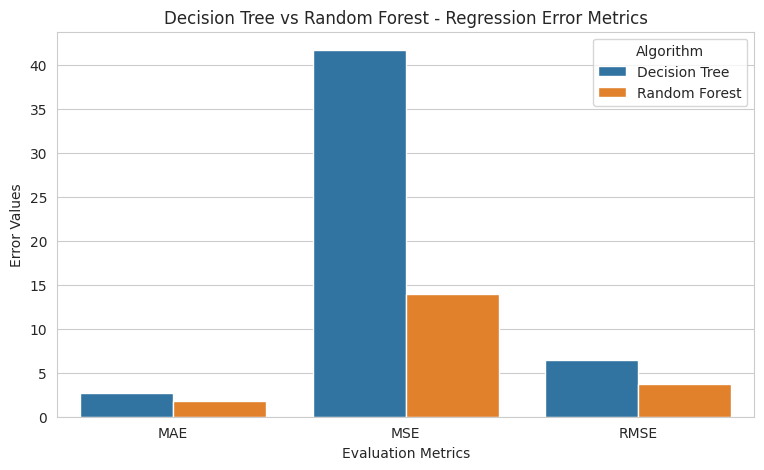

In [ ]:
# Creating a comparison table for error metrics
error_comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE'],
    'Decision Tree': [dt_mae, dt_mse, dt_rmse],
    'Random Forest': [rf_mae, rf_mse, rf_rmse]
})

# Converting the table into long format
error_plot = error_comparison.melt(
    id_vars='Metric',
    var_name='Algorithm',
    value_name='Score'
)

# Plotting the bar diagram
plt.figure(figsize=(9, 5))

sns.barplot(
    data=error_plot,
    x='Metric',
    y='Score',
    hue='Algorithm'
)

plt.title('Decision Tree vs Random Forest - Regression Error Metrics')
plt.xlabel('Evaluation Metrics')
plt.ylabel('Error Values')
plt.legend(title='Algorithm')
plt.show()

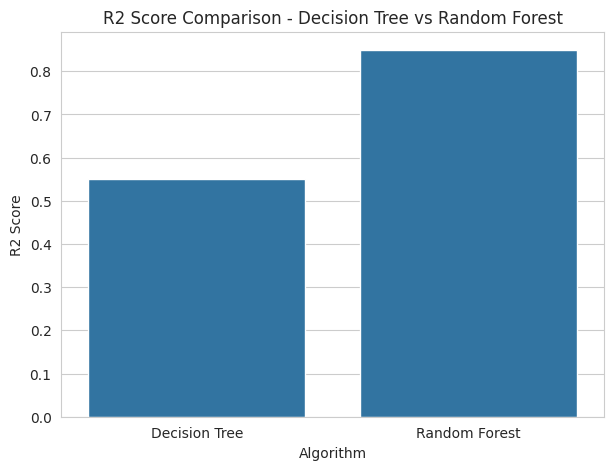

In [ ]:
# Creating a comparison table for R2 scores
r2_comparison = pd.DataFrame({
    'Algorithm': ['Decision Tree', 'Random Forest'],
    'R2 Score': [dt_r2, rf_r2]
})

# Plotting the bar diagram
plt.figure(figsize=(7, 5))

sns.barplot(
    data=r2_comparison,
    x='Algorithm',
    y='R2 Score'
)

plt.title('R2 Score Comparison - Decision Tree vs Random Forest')
plt.xlabel('Algorithm')
plt.ylabel('R2 Score')
plt.show()


### Conclusion – Regression Comparison

- Decision Tree Regressor and Random Forest Regressor were compared using MAE, MSE, RMSE and R² Score.
- Random Forest achieved a lower MAE (**1.8379**) compared to Decision Tree (**2.6526**), indicating that its predictions were closer to the actual fare amounts on average.
- Random Forest also obtained a lower MSE (**13.9560**) and RMSE (**3.7358**) compared to Decision Tree, indicating fewer and smaller prediction errors.
- Random Forest achieved a higher R² Score of **0.8492**, compared to **0.5497** for Decision Tree.
- The R² results indicate that Random Forest explains approximately **84.92%** of the variation in fare amounts, whereas Decision Tree explains approximately **54.97%**.
- Therefore, Random Forest Regressor demonstrated considerably better predictive performance across all the evaluation metrics.
- Hence, Random Forest Regressor was the better-performing algorithm for the given Uber Fare Prediction dataset.



# Overall Conclusion

Decision Tree and Random Forest algorithms were successfully implemented for both classification and regression tasks using the preprocessed Campus Placement Prediction and Uber Fare Prediction datasets.

For classification, Random Forest achieved better overall performance than Decision Tree in terms of Accuracy, Recall, F1-Score and ROC-AUC. However, Decision Tree performed slightly better in Precision and identifying students belonging to the Not Placed category.

For regression, Random Forest outperformed Decision Tree across all four evaluation metrics, achieving lower MAE, MSE and RMSE, along with a higher R² Score.

Bar diagrams, confusion matrices and ROC curves were plotted to visually compare the performances of the respective models.

Overall, Random Forest demonstrated better predictive performance for both classification and regression tasks, owing to its ensemble approach of combining multiple Decision Trees.


# Srabani Khuntia, 24BCSB03
# Roll No: 7, Group:E1